## **Real Estate Housing Price Prediction (Ridge & Lasso Regression)**

In [18]:
# Importing libraries
import warnings
warnings.filterwarnings("ignore")   # hides Lasso convergence warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

In [20]:
# Load data
df = pd.read_csv("housing.csv")
print(df.shape)                                        # rows, columns
print(df.isna().sum()[df.isna().sum() > 0])            # columns with missing values (only total_bedrooms)
print(df["ocean_proximity"].value_counts())            # the one categorical column

(20640, 10)
total_bedrooms    207
dtype: int64
ocean_proximity
<1H OCEAN     9136
INLAND        6551
NEAR OCEAN    2658
NEAR BAY      2290
ISLAND           5
Name: count, dtype: int64


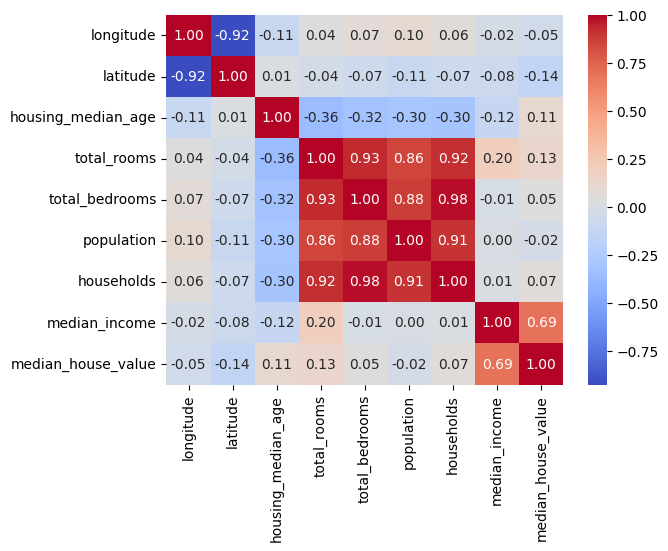

In [21]:
# Correlation heatmap
# Shows which features move together. total_rooms, total_bedrooms,
# population and households are strongly correlated with each other
sns.heatmap(df.select_dtypes("number").corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.show()

In [22]:
# New features
# Ratios are easier to interpret than raw district totals.
# Interaction terms let the model capture combined effects.
df["rooms_per_household"] = df["total_rooms"] / df["households"]            # home size
df["bedrooms_per_room"] = df["total_bedrooms"] / df["total_rooms"]          # share of rooms that are bedrooms
df["population_per_household"] = df["population"] / df["households"]        # crowding
df["income_x_age"] = df["median_income"] * df["housing_median_age"]         # interaction: income x house age
df["income_x_rooms"] = df["median_income"] * df["rooms_per_household"]      # interaction: income x home size
df["lat_x_lon"] = df["latitude"] * df["longitude"]                          # interaction: location
df["income_sq"] = df["median_income"] ** 2                                  # non-linear income effect

In [23]:
# Split
# 80% to train, 20% to test. We split BEFORE imputing and scaling
# so the test set never influences the training (no data leakage).
X = df.drop(columns="median_house_value")     # features
y = df["median_house_value"]                  # target to predict
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(X_train.shape, X_test.shape)

(16512, 16) (4128, 16)


In [24]:
# Preprocessing: impute + scale numbers, one-hot encode category
# Numeric columns: fill missing values with the median, then standardize (mean 0, std 1) so Ridge/Lasso penalize all features fairly.
# Category column: one-hot encode (drop="first" avoids a redundant column).
num_cols = [c for c in X.columns if c != "ocean_proximity"]
prep = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), num_cols),
    ("cat", OneHotEncoder(drop="first"), ["ocean_proximity"]),
])

In [17]:
# MODELS
# Each model is a Pipeline: preprocessing first, then the regression.
# OLS: plain linear regression, no penalty (our baseline)
ols = Pipeline([("prep", prep), ("m", LinearRegression())]).fit(X_train, y_train)

# Ridge (L2): shrinks coefficients toward zero. GridSearchCV tries 25 alpha
# values with 5-fold cross-validation and keeps the one with the lowest RMSE.
ridge = GridSearchCV(Pipeline([("prep", prep), ("m", Ridge())]),
                     {"m__alpha": np.logspace(-2, 4, 25)},
                     scoring="neg_root_mean_squared_error", cv=5)
ridge.fit(X_train, y_train)

# Lasso (L1): can shrink some coefficients exactly to zero (feature selection).
# Alphas below ~10 converge very slowly on these correlated features, so the grid starts at 10.
lasso = GridSearchCV(Pipeline([("prep", prep), ("m", Lasso(max_iter=20000))]),
                     {"m__alpha": np.logspace(1, 4, 16)},
                     scoring="neg_root_mean_squared_error", cv=5)
lasso.fit(X_train, y_train)

# Best alpha found by cross-validation (CV RMSE = error on the validation folds)
print("Best Ridge alpha:", round(ridge.best_params_["m__alpha"], 3), "| CV RMSE:", round(-ridge.best_score_))
print("Best Lasso alpha:", round(lasso.best_params_["m__alpha"], 3), "| CV RMSE:", round(-lasso.best_score_))

Best Ridge alpha: 0.01 | CV RMSE: 66907
Best Lasso alpha: 10.0 | CV RMSE: 66987


In [19]:
# COMPARE MODELS: RMSE, MAE, R² on train and test sets
# RMSE / MAE: average error in dollars (lower is better)
# R²: share of variance explained (higher is better)
models = {"OLS": ols, "Ridge": ridge.best_estimator_, "Lasso": lasso.best_estimator_}
rows = []
for name, m in models.items():
    for split, Xs, ys in [("train", X_train, y_train), ("test", X_test, y_test)]:
        p = m.predict(Xs)
        rows.append([name, split, np.sqrt(mean_squared_error(ys, p)),
                     mean_absolute_error(ys, p), r2_score(ys, p)])
print(pd.DataFrame(rows, columns=["model", "split", "RMSE", "MAE", "R2"]).round(4))


   model  split        RMSE         MAE      R2
0    OLS  train  66625.1729  48397.3243  0.6679
1    OLS   test  68571.6052  49251.1398  0.6412
2  Ridge  train  66625.2295  48397.3739  0.6679
3  Ridge   test  68573.5999  49252.8408  0.6412
4  Lasso  train  66706.5325  48472.2570  0.6671
5  Lasso   test  68726.3973  49398.0522  0.6396


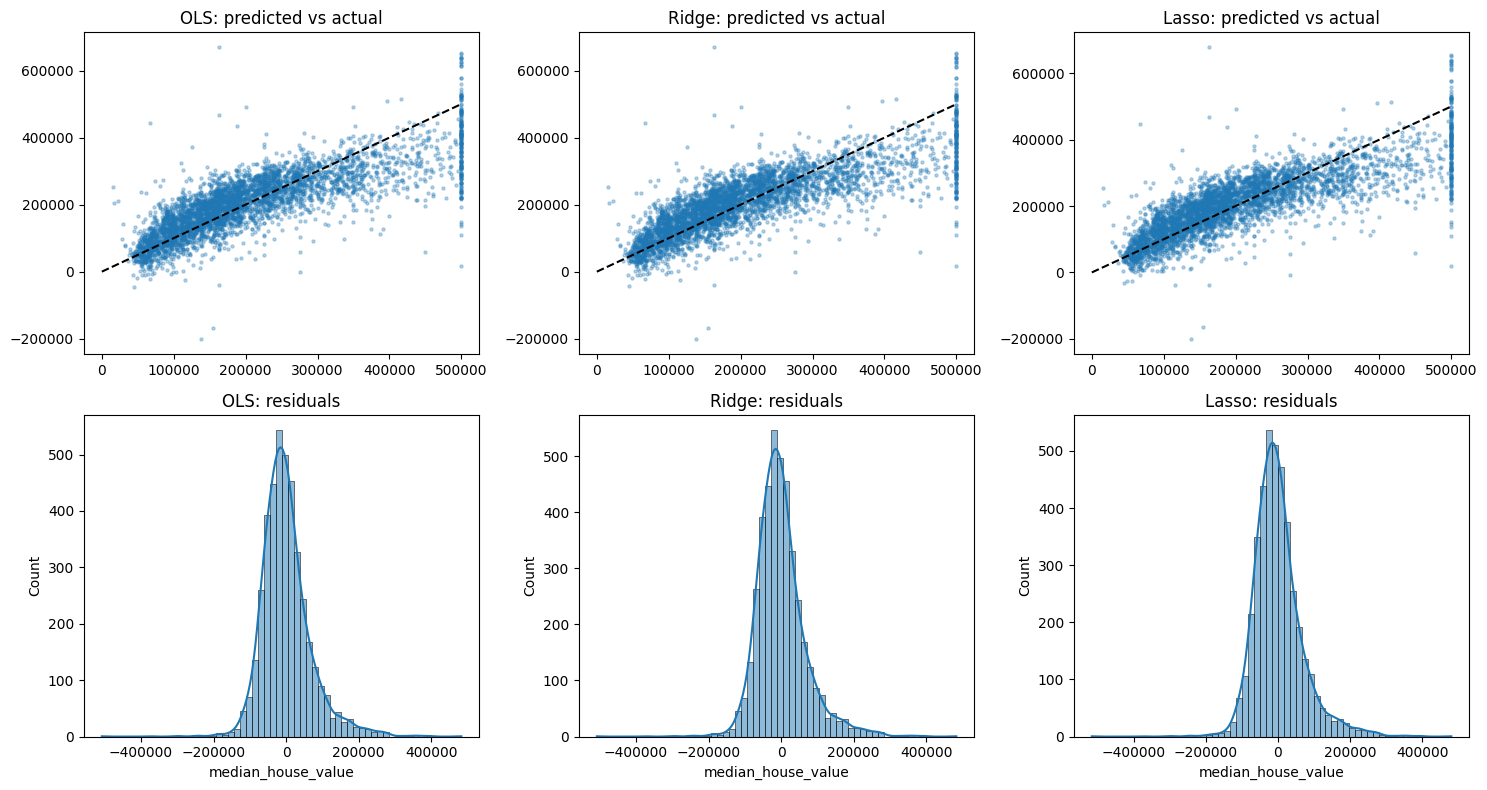

In [25]:
# Plots: predicted vs actual, residual distribution
# Top row: predicted vs actual. Points on the dashed line = perfect predictions.
# Bottom row: residual (actual - predicted) distribution. Should be centered at 0.
# The right skew shows the model under-predicts expensive homes.
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for i, (name, m) in enumerate(models.items()):
    pred = m.predict(X_test)
    resid = y_test - pred
    axes[0, i].scatter(y_test, pred, s=5, alpha=0.3)
    axes[0, i].plot([0, 500000], [0, 500000], "k--")
    axes[0, i].set_title(f"{name}: predicted vs actual")
    sns.histplot(resid, bins=60, kde=True, ax=axes[1, i])
    axes[1, i].set_title(f"{name}: residuals")
plt.tight_layout()
plt.show()